# 🌊 03 - Seaborn: Distributions

Module 07 described a column's **shape** with numbers: center, spread, skew, outliers. This notebook draws the shape itself, and compares it across groups, straight from the raw rows.

**Seaborn** is a library built on Matplotlib for statistical charts. You name the **columns** you want on each part of the chart (`x=`, `y=`, `hue=`, `col=`), and Seaborn does the grouping, counting, and coloring for you. That's why it wants **long** data (notebook 02): one row per observation.

## ✅ Learning Goals
- Explain Seaborn's column-mapping model (`data=`, `x=`, `hue=`, ...) and **axes-level** vs. **figure-level** functions
- Draw histograms with `sns.histplot()`, and control bins, `hue`, `multiple=`, `stat=`, and `common_norm=`
- Compare groups of different sizes fairly with `stat='density'` / `'percent'` and `common_norm=False`
- Use KDE and ECDF plots, and know when each helps
- Read a box plot as Module 07's quartiles and IQR fences, and combine it with violin and strip plots
- Build small multiples with `sns.displot(col=...)`

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

OUT = Path('03-OutputFiles')
OUT.mkdir(exist_ok=True)

sns.set_theme(style='whitegrid')       # one call styles every chart that follows

MEASUREMENTS = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# Same cleaning as the Module 07 lab
penguins = pd.read_csv('penguins.csv').dropna(subset=MEASUREMENTS)
penguins['sex'] = penguins['sex'].str.title()

titanic = pd.read_csv('titanic.csv')
titanic['outcome'] = titanic['Survived'].map({0: 'died', 1: 'survived'})

# Reproducible jitter and accessible, consistent group colors.
import numpy as np
np.random.seed(21)
sns.set_palette('colorblind')
SPECIES_ORDER = ['Adelie', 'Chinstrap', 'Gentoo']
SPECIES_PALETTE = dict(zip(SPECIES_ORDER, sns.color_palette('colorblind', 3)))


## 1. The Seaborn Model
Every Seaborn function takes a DataFrame and **maps columns to roles**:

```python
sns.histplot(data=penguins, x='body_mass_g', hue='species')
#            the table      the x-axis       color by this column
```

Functions come in two levels:

| Level | Examples | Draws on | Returns | Size with |
|---|---|---|---|---|
| **Axes-level** | `histplot`, `kdeplot`, `boxplot`, `violinplot`, `scatterplot` | one `ax` (pass `ax=` to choose) | an `ax` | `plt.subplots(figsize=...)` |
| **Figure-level** | `displot`, `catplot`, `relplot` | a whole new figure, one panel per group (`col=`, `row=`) | a `FacetGrid` | `height=`, `aspect=` |

Axes-level functions slot into the `fig, ax` workflow from notebook 01. Figure-level functions build the panels for you.

## 2. Histograms with `sns.histplot()`

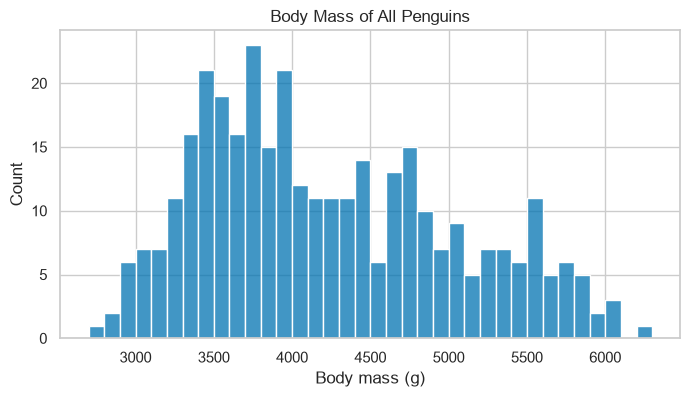

In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=penguins, x='body_mass_g', binwidth=100, ax=ax)
ax.set(title='Body Mass of All Penguins', xlabel='Body mass (g)')
plt.show()

Module 07 said body mass was roughly symmetric overall (skew ≈ 0.47). The histogram shows something the skew number couldn't: a big pile on the left, then a long, lumpy **shoulder** on the right that doesn't taper off smoothly. That's a hint that two different groups may be mixed together. (When the groups are far enough apart to make two clear peaks, the distribution is called **bimodal**.)

`binwidth=100` sets each bar to 100 g wide. You can set the number of bars with `bins=` instead. As Foundations 07 showed, the choice changes what you see, so try a few.

## 3. Groups with `hue`
`hue='species'` splits the data by species and colors each group:

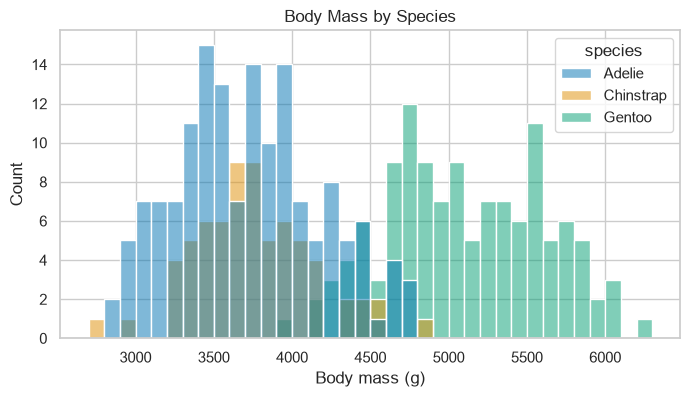

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=penguins, x='body_mass_g', hue='species', binwidth=100, ax=ax)
ax.set(title='Body Mass by Species', xlabel='Body mass (g)')
plt.show()

There's the second group: **Gentoos**, making up most of that right shoulder. Adelies and Chinstraps overlap almost completely. That matches the Module 07 lab's species summary (Gentoo mean ≈ 5,076 g vs. about 3,700 g for the others), but now you can see the whole distribution, not just one number per group.

Overlapping bars get hard to read. `multiple=` controls how the groups share the space:

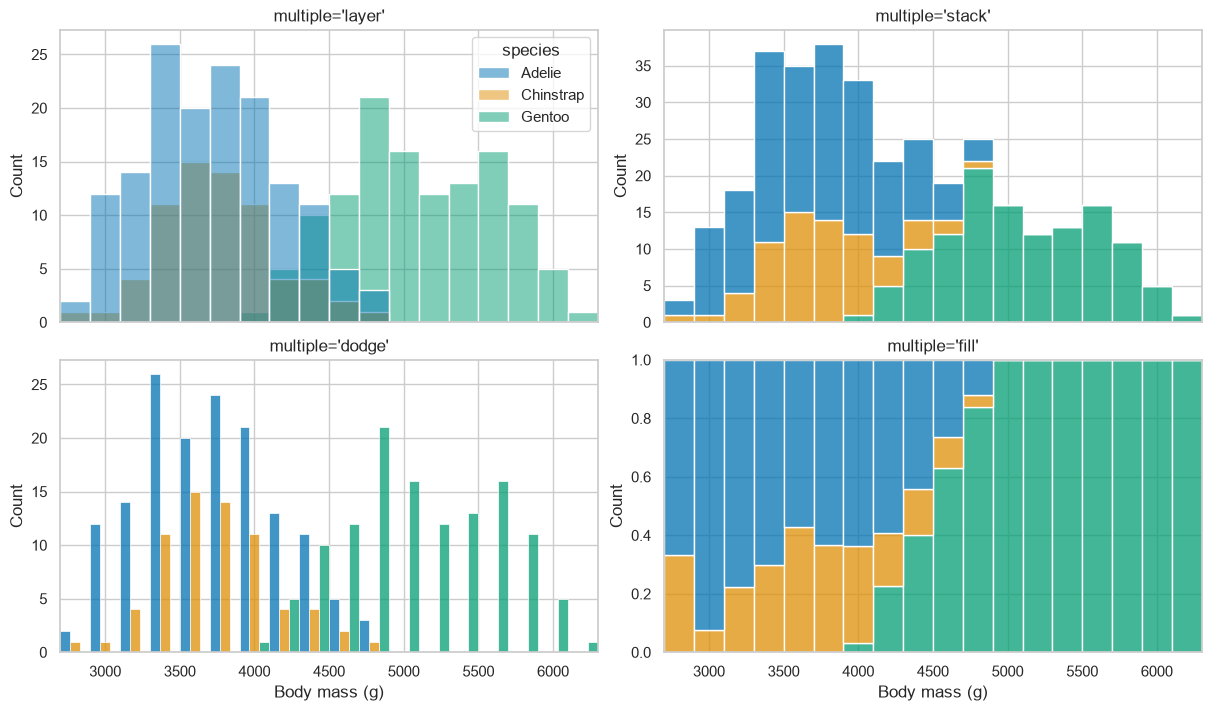

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout='constrained')

for ax, how in zip(axes.flat, ['layer', 'stack', 'dodge', 'fill']):
    sns.histplot(data=penguins, x='body_mass_g', hue='species', binwidth=200,
                 multiple=how, ax=ax, legend=(how == 'layer'))
    ax.set(title=f"multiple='{how}'", xlabel='Body mass (g)')

plt.show()

| `multiple=` | Shows | Good for |
|---|---|---|
| `'layer'` (default) | groups drawn on top of each other, semi-transparent | 2–3 groups that don't overlap much |
| `'stack'` | groups piled up | the **total**, plus each group's part of it |
| `'dodge'` | bars side by side within each bin | comparing groups bin by bin |
| `'fill'` | each bin stretched to 100% | the **mix** of groups at each value |

`element='step'` (outlines instead of filled bars) is another fix for overlap.

## 4. Fair Comparisons: `stat=` and `common_norm=`
Module 07 notebook 04: when groups have different sizes, compare **rates**, not counts. Histograms have the same problem. Compare the ages of Titanic passengers who survived and who died:

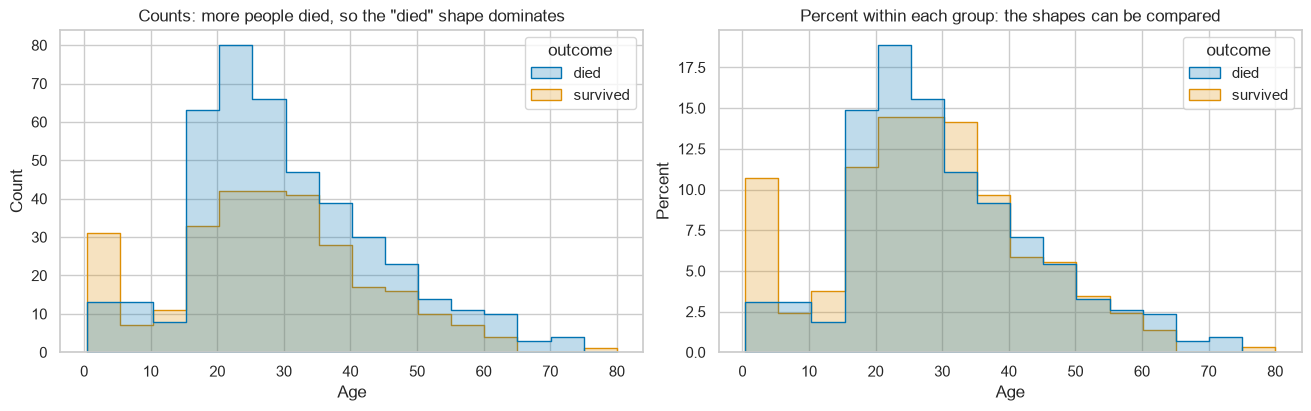

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')

sns.histplot(data=titanic, x='Age', hue='outcome', binwidth=5, element='step', ax=axes[0])
axes[0].set(title='Counts: more people died, so the "died" shape dominates')

sns.histplot(data=titanic, x='Age', hue='outcome', binwidth=5, element='step',
             stat='percent', common_norm=False, ax=axes[1])
axes[1].set(title='Percent within each group: the shapes can be compared')

plt.show()

- `stat='percent'` (or `'density'`) puts the y-axis on a relative scale instead of raw counts.
- `common_norm=False` makes **each group** add up to 100% on its own. With the default (`True`), the percentages are of everyone combined, and the bigger group still looks bigger.

In the right-hand chart, survivors are noticeably more common in the youngest bins (children). The left-hand chart nearly hides that.

✅ **Your Turn:** Make the right-hand chart for `Fare` instead of `Age`, using a log x-axis (`log_scale=True`, a `histplot` argument). Which group paid more?

Excluded zero fares only from this log chart: 15
Positive-fare counts and medians:
          size  median       mean
outcome                          
died       535    10.5  22.696673
survived   341    26.0  48.537330


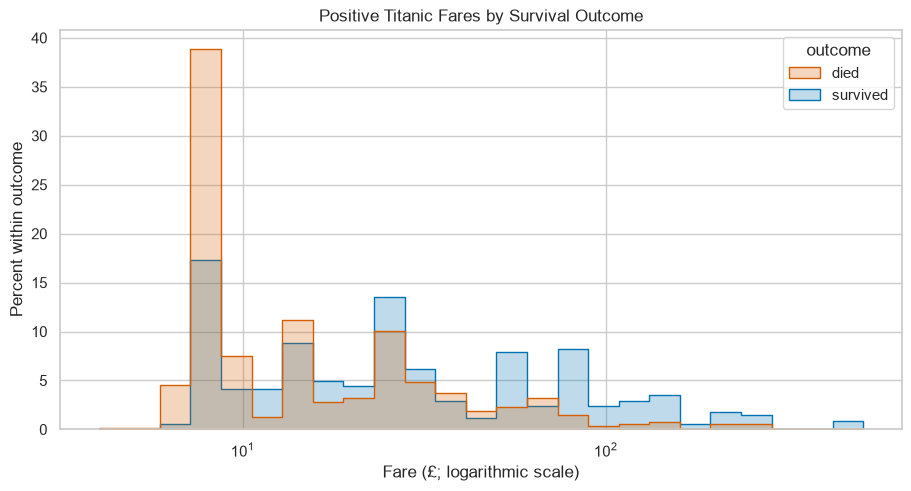

In [6]:
# Your turn here

# Log axes require strictly positive fares; preserve the raw Titanic table.
positive_fares = titanic.loc[titanic['Fare'].gt(0)].copy()
print('Excluded zero fares only from this log chart:', titanic['Fare'].eq(0).sum())
print('Positive-fare counts and medians:')
print(positive_fares.groupby('outcome')['Fare'].agg(['size', 'median', 'mean']).to_string())
fig, ax = plt.subplots(figsize=(9, 4.8), layout='constrained')
sns.histplot(data=positive_fares, x='Fare', hue='outcome',
             hue_order=['died', 'survived'], palette=['#D55E00', '#0072B2'],
             bins=25, element='step', stat='percent', common_norm=False,
             log_scale=True, ax=ax)
ax.set(title='Positive Titanic Fares by Survival Outcome',
       xlabel='Fare (£; logarithmic scale)', ylabel='Percent within outcome')
fig.savefig(OUT / 'fare_by_outcome_log.png', dpi=150, bbox_inches='tight')
plt.show()


**Fare response:** Survivors tended to pay more: among positive fares, their median is £26 versus £10.5 for those who died. All 15 zero fares are excluded only from this chart because log(0) is undefined; the exact positive counts are printed by outcome above. The normalized histogram describes fare distributions within outcomes, not the probability of survival at a given fare, and class confounds a causal interpretation.

## 5. Smooth Shapes: KDE Plots
A **kernel density estimate (KDE)** draws a smooth curve instead of bars. It's easier to compare several groups when the curves overlap:

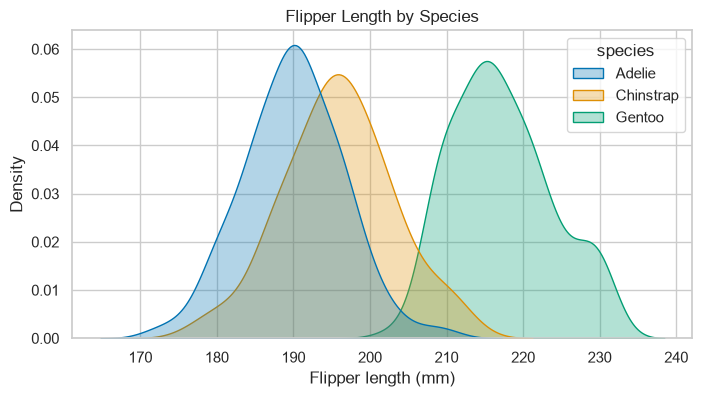

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(data=penguins, x='flipper_length_mm', hue='species', fill=True, alpha=0.3,
            common_norm=False, ax=ax)
ax.set(title='Flipper Length by Species', xlabel='Flipper length (mm)')
plt.show()

Two cautions:
- **Smoothing is a choice.** `bw_adjust=` controls it: lower is more wiggly, higher is smoother. Like bin width, too much hides real detail.
- **A KDE can spill past what's possible**, such as negative ages or fares. Add `cut=0` to stop the curve at the data's actual min and max.

`sns.histplot(..., kde=True)` draws the curve on top of the bars, if you want both.

## 6. Reading Percentiles Directly: ECDF Plots
An **ECDF** (empirical cumulative distribution function) plots, for every value, **the share of data at or below it**. No bins, no smoothing, every point shown. You can read Module 07's percentiles straight off the y-axis:

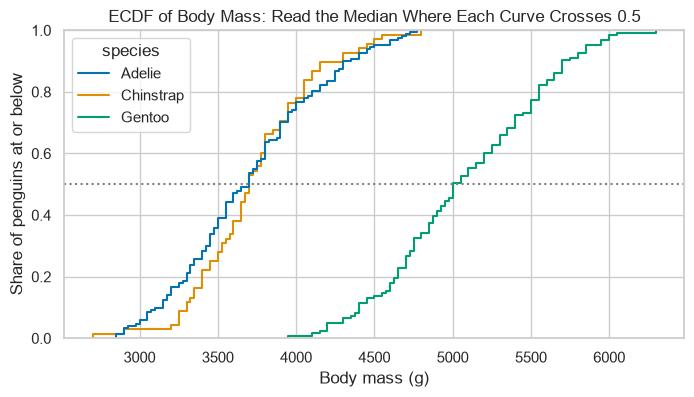

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.ecdfplot(data=penguins, x='body_mass_g', hue='species', ax=ax)
ax.axhline(0.5, color='gray', linestyle=':')
ax.set(title='ECDF of Body Mass: Read the Median Where Each Curve Crosses 0.5',
       xlabel='Body mass (g)', ylabel='Share of penguins at or below')
plt.show()

Where a species' curve crosses the dotted 0.5 line is its **median**. A curve further right means a heavier species. A steeper curve means less spread.

## 7. Box Plots, Revisited
A box plot is Module 07 notebook 03 drawn as a picture:

```text
   o            ← outlier: beyond the fence
   ┬            ← whisker: the most extreme value INSIDE the fence
 ┌─┴─┐
 │   │          ← Q3 (75th percentile)
 ├───┤          ← median
 │   │          ← Q1 (25th percentile)
 └─┬─┘          box height = IQR
   ┴
```

The fences are exactly the `iqr_fences()` from Module 07. Check that on Titanic fares in 1st class:

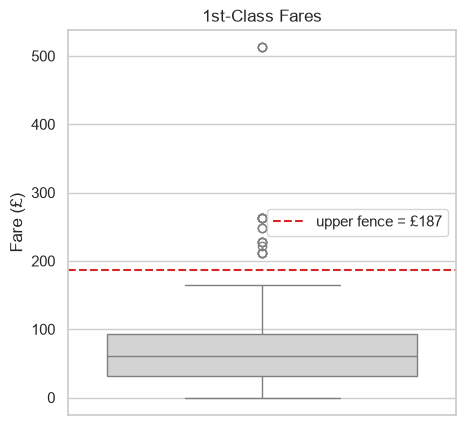

Points beyond the fence: 20


In [9]:
def iqr_fences(series, k=1.5):
    """Return the (lower, upper) outlier fences for a numeric Series."""
    q1, q3 = series.quantile([0.25, 0.75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)


first = titanic[titanic['Pclass'] == 1]['Fare']
low, high = iqr_fences(first)

fig, ax = plt.subplots(figsize=(5, 5))
sns.boxplot(y=first, ax=ax, color='lightgray')
ax.axhline(high, color='tab:red', linestyle='--', label=f'upper fence = £{high:.0f}')
ax.set(title='1st-Class Fares', ylabel='Fare (£)')
ax.legend(loc='center right')
plt.show()

print('Points beyond the fence:', (first > high).sum())

Every dot above the red line is a value `iqr_fences()` would flag, and the whisker stops at the last value inside the fence.

### Comparing groups
Box plots shine for comparing **many** groups side by side. `order=` sets the order of the boxes (Module 07 notebook 01: order means something, so choose it on purpose):

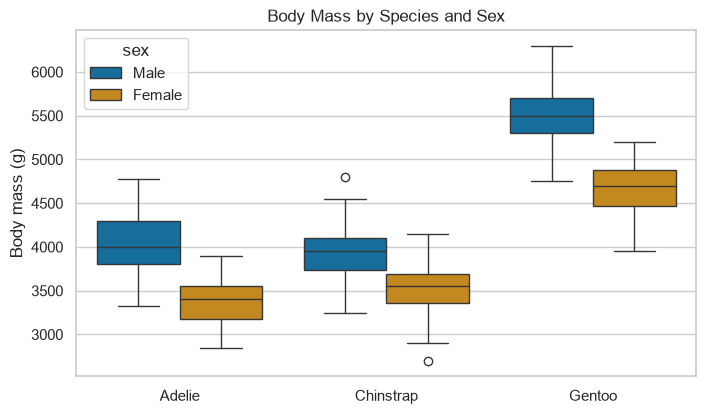

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=penguins, x='species', y='body_mass_g', hue='sex',
            order=['Adelie', 'Chinstrap', 'Gentoo'], ax=ax)
ax.set(title='Body Mass by Species and Sex', xlabel='', ylabel='Body mass (g)')
plt.show()

## 8. What a Box Hides: Violin and Strip Plots
A box plot reduces each group to five numbers, so it can't show a second peak, or how many points there are. Two complements:
- **Violin plot**: a KDE turned sideways and mirrored, so it shows the full shape.
- **Strip plot**: every individual point, with a little random sideways **jitter** so they don't sit on top of each other.

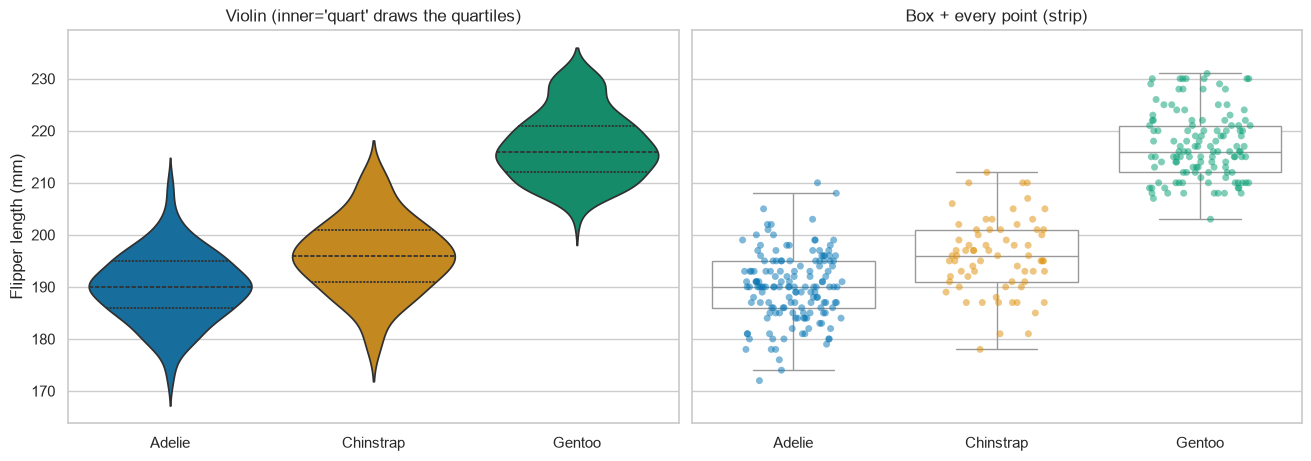

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True, layout='constrained')

sns.violinplot(data=penguins, x='species', y='flipper_length_mm', inner='quart',
               hue='species', legend=False, ax=axes[0])
axes[0].set(title="Violin (inner='quart' draws the quartiles)", xlabel='', ylabel='Flipper length (mm)')

sns.boxplot(data=penguins, x='species', y='flipper_length_mm', color='white',
            showfliers=False, ax=axes[1])
sns.stripplot(data=penguins, x='species', y='flipper_length_mm', hue='species',
              alpha=0.5, jitter=0.25, legend=False, ax=axes[1])
axes[1].set(title='Box + every point (strip)', xlabel='')

fig.savefig(OUT / 'flipper_violin_strip.png', dpi=150, bbox_inches='tight')
plt.show()

`showfliers=False` hides the box plot's own outlier dots, because the strip plot already draws every point (otherwise outliers would appear twice).

| Chart | Shows | Best when |
|---|---|---|
| Box | 5-number summary + outliers | many groups, quick comparison |
| Violin | full shape (peaks, skew) | shape matters, groups are large |
| Strip / swarm | every point | small to medium groups, and you want to see n |
| Box + strip | summary **and** every point | a clear default for a few groups |

## 9. Small Multiples with `sns.displot()`
`hue` puts all groups on one chart. When they overlap too much, give each group its **own panel** instead. Figure-level `displot` does it with `col=` (and `row=`):

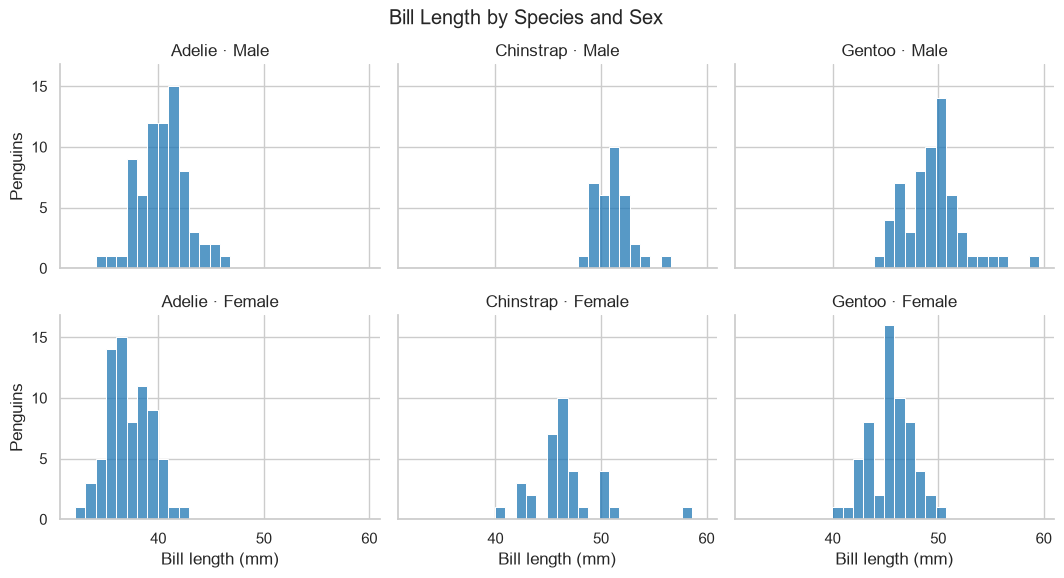

In [12]:
g = sns.displot(data=penguins, x='bill_length_mm', col='species', row='sex',
                binwidth=1, height=2.8, aspect=1.3, color='tab:blue')
g.set_axis_labels('Bill length (mm)', 'Penguins')
g.set_titles('{col_name} · {row_name}')
g.figure.suptitle('Bill Length by Species and Sex', y=1.03)
g.savefig(OUT / 'bill_length_grid.png', dpi=150, bbox_inches='tight')
plt.show()

**Group sizes and missing sex:** The measured penguin dataset contains 151 Adelies, 68 Chinstraps, and 123 Gentoos (342 total). Charts without sex retain all nine measured birds with unknown sex. The species/sex box plot and bill-length grid require known sex, so they display 333 birds: Adelie 73 Male/73 Female, Chinstrap 34/34, and Gentoo 61/58. Unknown sex is not assigned or imputed. These exclusions apply only to charts that map sex.

Every panel shares the same axes, so you can compare any two panels directly (notebook 01's `sharey=True`, done for you). Figure-level functions are sized with `height=` (inches per panel) and `aspect=` (width ÷ height), not `figsize`. The returned `FacetGrid` has its own methods: `set_axis_labels`, `set_titles`, `savefig`, and `g.figure` for the whole figure.

---
### 📝 Summary
- Seaborn maps **columns to roles** (`x`, `y`, `hue`, `col`, `row`) on **long** data.
- Axes-level functions (`histplot`, `boxplot`, ...) take `ax=`. Figure-level ones (`displot`, `catplot`, `relplot`) build a grid of panels.
- `histplot`: choose `binwidth`/`bins`, separate groups with `multiple=`, and compare groups of different sizes with `stat='percent'` + `common_norm=False`.
- KDE for smooth comparison (watch `bw_adjust` and `cut=0`). ECDF for reading percentiles.
- A box plot **is** the IQR fence rule. Violins show shape, and strips show every point.
- Overlapping `hue` groups? Use small multiples with `col=`/`row=`.

## 🏋️ Practice

### Practice 1 — Bill Depth by Species (easy)
Make a `histplot` of `bill_depth_mm` with `hue='species'` and `element='step'`. Which species stands apart, and in which direction? Does that match the Module 07 lab's species summary?

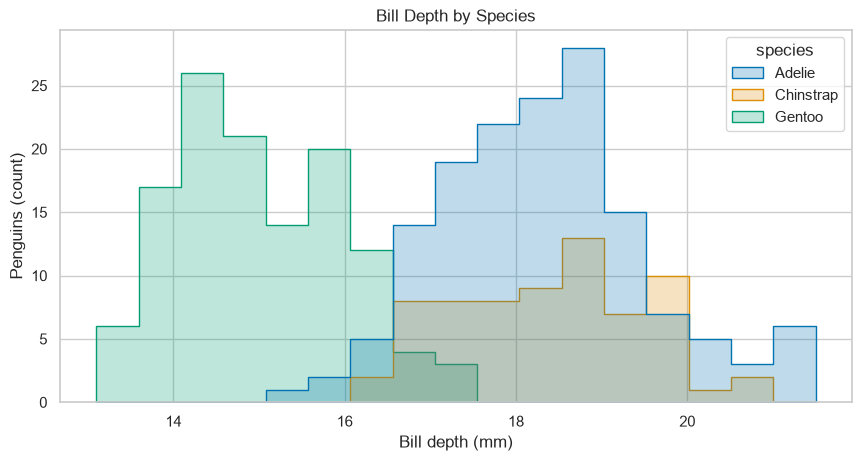

           size       mean  median
species                           
Adelie      151  18.346358   18.40
Chinstrap    68  18.420588   18.45
Gentoo      123  14.982114   15.00


In [13]:
# Your code here

fig, ax = plt.subplots(figsize=(8.5, 4.5), layout='constrained')
sns.histplot(data=penguins, x='bill_depth_mm', hue='species',
             hue_order=SPECIES_ORDER, palette=SPECIES_PALETTE,
             element='step', binwidth=.5, ax=ax)
ax.set(title='Bill Depth by Species', xlabel='Bill depth (mm)', ylabel='Penguins (count)')
fig.savefig(OUT / 'bill_depth_by_species.png', dpi=150, bbox_inches='tight')
plt.show()
print(penguins.groupby('species')['bill_depth_mm'].agg(['size', 'mean', 'median']).to_string())


**Practice 1 response:** Gentoo stands apart toward shallower bills: mean depth is approximately 14.98 mm, compared with Adelie 18.35 mm and Chinstrap 18.42 mm. This matches the Module 07 species summary. All 342 measured penguins contribute, including nine with unknown sex, because neither axis uses sex.

### Practice 2 — Pokémon Totals (medium)
Load `pokemon.csv`. Draw `Total` by `Legendary` two ways, side by side in one figure: (a) a histogram with **counts**, and (b) a histogram with `stat='density', common_norm=False`. In a Markdown cell, explain why the Legendary distribution is nearly invisible in (a).

           size        mean  median
Legendary                          
False       735  417.213605   425.0
True         65  637.384615   600.0


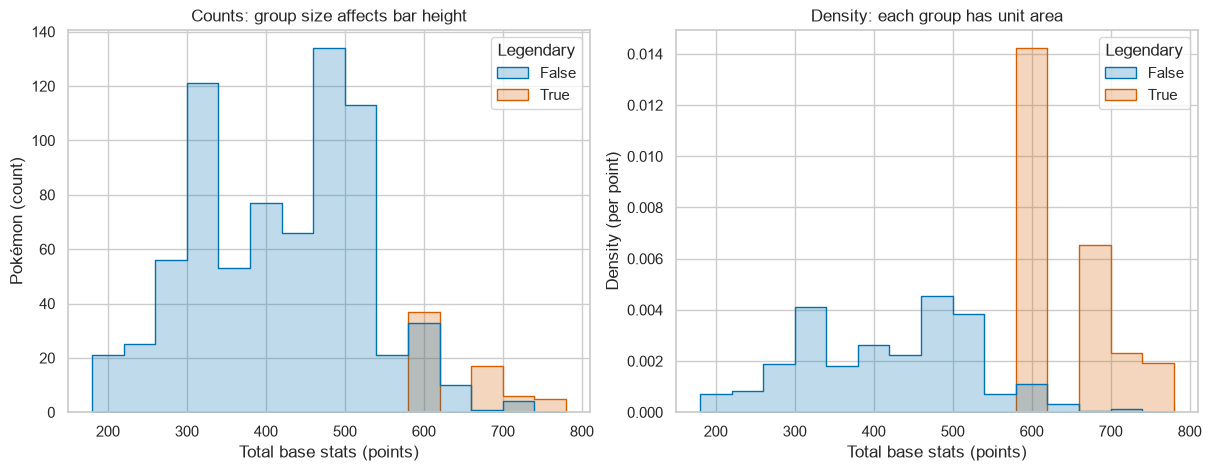

In [14]:
# Your code here

poke = pd.read_csv('pokemon.csv')
print(poke.groupby('Legendary')['Total'].agg(['size', 'mean', 'median']).to_string())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout='constrained')
for ax, statistic, title in zip(axes, ['count', 'density'],
        ['Counts: group size affects bar height', 'Density: each group has unit area']):
    sns.histplot(data=poke, x='Total', hue='Legendary', hue_order=[False, True],
                 palette={False: '#0072B2', True: '#D55E00'}, binwidth=40,
                 element='step', stat=statistic, common_norm=False, ax=ax)
    ax.set(title=title, xlabel='Total base stats (points)',
           ylabel='Pokémon (count)' if statistic == 'count' else 'Density (per point)')
fig.savefig(OUT / 'pokemon_totals_counts_density.png', dpi=150, bbox_inches='tight')
plt.show()


*Your explanation here.*

**Response:** There are 735 non-Legendary Pokémon but only 65 Legendary Pokémon. Count histograms give the much larger group many more observations to distribute across bins, so the smaller group's shape is harder to see. With density and `common_norm=False`, each group's histogram has total area 1 independently; this compares distribution shapes instead of group size. Legendary totals tend to be higher (median 600 versus 425), though the distributions overlap.

### Practice 3 — Box vs. Violin vs. Strip (harder)
For Titanic `Age` by `class` (create it with `.map()`), draw a 1 × 3 figure: box plot, violin plot, and box + strip. Use the same `order=['1st', '2nd', '3rd']` in every panel. Which chart makes it clearest that 3rd class had many more passengers? Which shows the cluster of young children best?

Known-age versus all passengers:
       all_passengers  known_ages
class                            
1st               216         186
2nd               184         173
3rd               491         355
Children under 10: {'1st': 3, '2nd': 17, '3rd': 42}


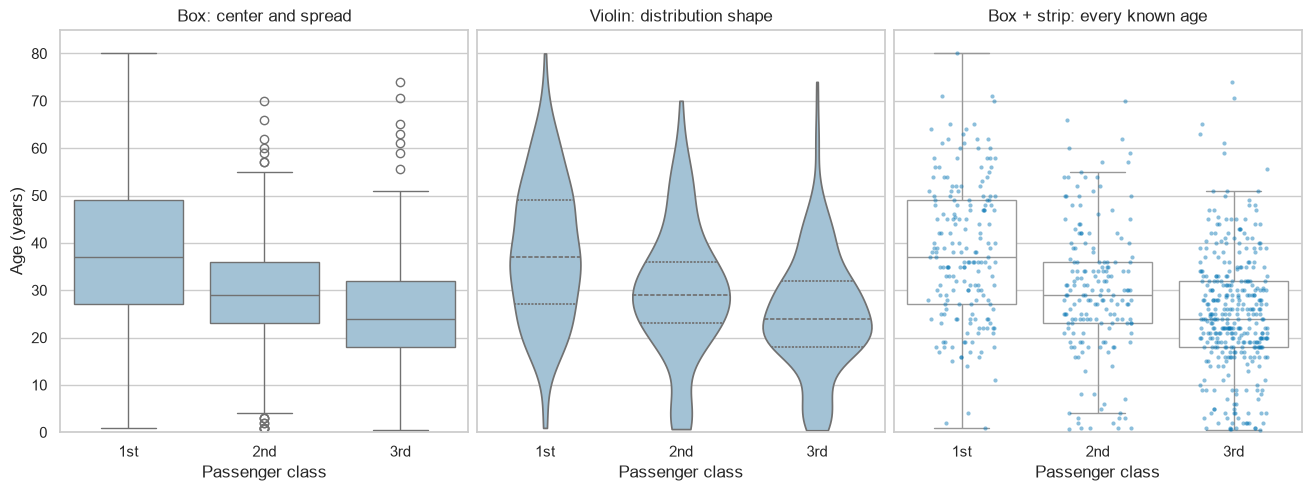

In [15]:
# Your code here

titanic['class'] = titanic['Pclass'].map({1: '1st', 2: '2nd', 3: '3rd'})
CLASS_ORDER = ['1st', '2nd', '3rd']
age_known = titanic.dropna(subset=['Age']).copy()
print('Known-age versus all passengers:')
print(titanic.groupby('class').agg(all_passengers=('PassengerId', 'size'),
    known_ages=('Age', 'count')).reindex(CLASS_ORDER).to_string())
print('Children under 10:', age_known.loc[age_known.Age < 10].groupby('class').size().reindex(CLASS_ORDER).to_dict())
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), sharey=True, layout='constrained')
sns.boxplot(data=age_known, x='class', y='Age', order=CLASS_ORDER,
            color='#9BC4DD', ax=axes[0])
sns.violinplot(data=age_known, x='class', y='Age', order=CLASS_ORDER,
               color='#9BC4DD', cut=0, inner='quart', ax=axes[1])
sns.boxplot(data=age_known, x='class', y='Age', order=CLASS_ORDER,
            color='white', showfliers=False, ax=axes[2])
sns.stripplot(data=age_known, x='class', y='Age', order=CLASS_ORDER,
              color='#0072B2', size=3, alpha=.45, jitter=.25, ax=axes[2])
for ax, title in zip(axes, ['Box: center and spread', 'Violin: distribution shape', 'Box + strip: every known age']):
    ax.set(title=title, xlabel='Passenger class', ylabel='Age (years)')
    ax.set_ylim(0, 85)
fig.savefig(OUT / 'titanic_age_box_violin_strip.png', dpi=150, bbox_inches='tight')
plt.show()


*Your answer here.*

**Response:** Box + strip makes the larger third-class sample clearest because every known-age passenger contributes a point: 355 third-class ages, versus 186 first-class and 173 second-class ages. Neither equal-width boxes nor the default equal-area violin widths represent sample counts. The violin makes the concentration of young third-class children visible as a low-age bulge, while the strip confirms the individual ages; there are 42 third-class children under 10, versus 3 first-class and 17 second-class. Missing ages are excluded from all three panels (177 passengers), so the plotted counts are not total passenger counts.

## ✏️ Your Turn
Use `sns.displot()` to draw `body_mass_g` with `col='island'` and `hue='species'`. Save it as `OUT / 'mass_by_island.png'`. Then, in a Markdown cell, connect it to the Module 07 lab: why would comparing "island" averages be misleading?

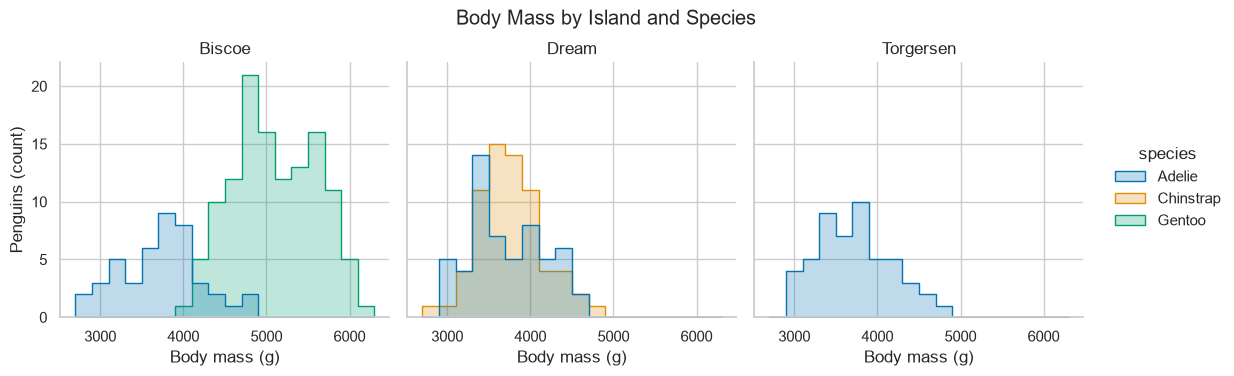

species    Adelie  Chinstrap  Gentoo
island                              
Biscoe         44          0     123
Dream          56         68       0
Torgersen      51          0       0


In [16]:
# Your turn here

g = sns.displot(data=penguins, x='body_mass_g', col='island', hue='species',
                col_order=['Biscoe', 'Dream', 'Torgersen'], hue_order=SPECIES_ORDER,
                palette=SPECIES_PALETTE, binwidth=200, element='step',
                height=3.6, aspect=1.05)
g.set_axis_labels('Body mass (g)', 'Penguins (count)')
g.set_titles('{col_name}')
g.figure.suptitle('Body Mass by Island and Species', y=1.04)
g.savefig(OUT / 'mass_by_island.png', dpi=150, bbox_inches='tight')
plt.show()
print(pd.crosstab(penguins['island'], penguins['species']).to_string())


*Your explanation here.*

**Response:** Biscoe contains 123 Gentoos and 44 Adelies; Dream has 68 Chinstraps and 56 Adelies; Torgersen has 51 Adelies only. Gentoo body masses are much higher on average, so a high pooled Biscoe mean mixes species composition with island. Compare the same species across islands—Adelie is observed on all three—and consider sex or other sampling differences before interpreting an island effect.

## 🔥 Challenge (Optional) — Bin Width Experiment
Write a loop that draws `body_mass_g` (all penguins, no `hue`) in a 1 × 4 figure with `binwidth` of 25, 100, 250, and 800. At which width is the right shoulder (the Gentoos) easiest to see, and at which does it disappear? Add a fifth panel with `sns.kdeplot(..., bw_adjust=...)` set so smooth that it hides the shoulder. What does that tell you about trusting a single chart?

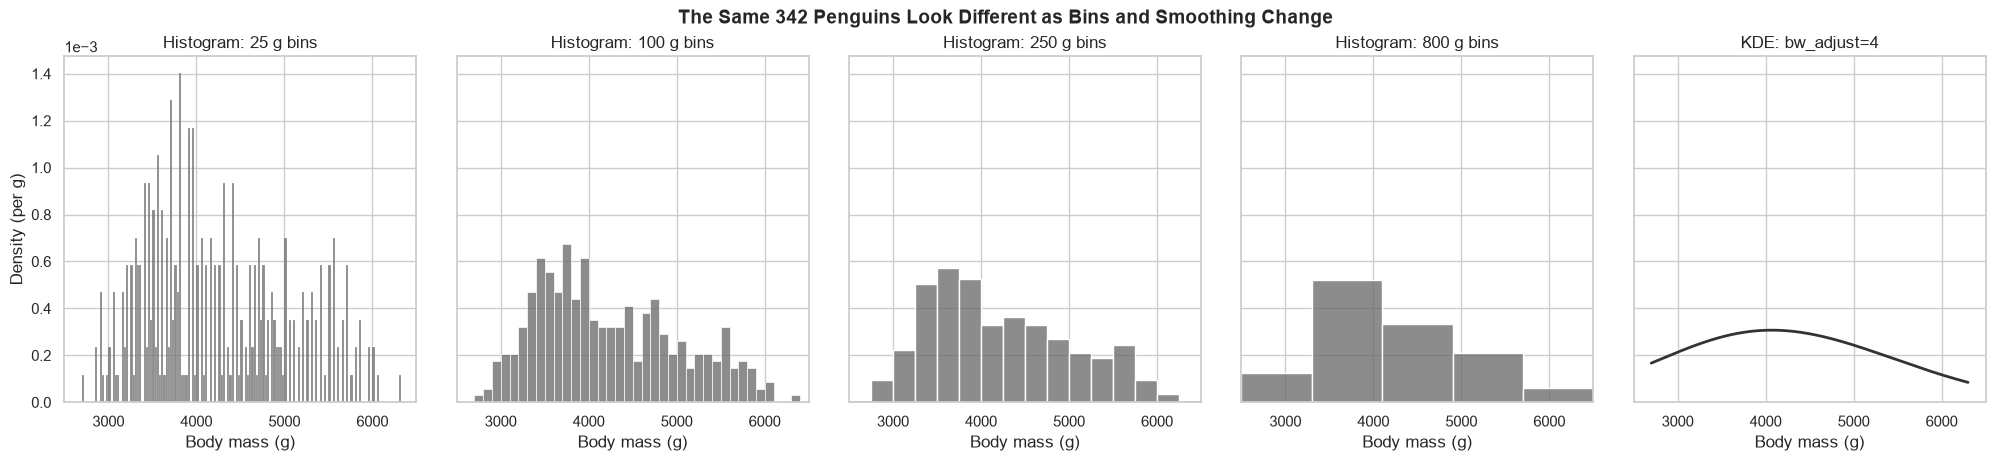

PASS: all four histograms contain 342 birds; oversmoothed KDE has one broad maximum.


In [17]:
# Your code here

# Optional: one figure, four exact bin widths plus an oversmoothed KDE.
# Use density for all panels, so bins with different widths have area 1.
widths = [25, 100, 250, 800]
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5), sharex=True, sharey=True,
                         layout='constrained')
for ax, width in zip(axes[:4], widths):
    sns.histplot(data=penguins, x='body_mass_g', binwidth=width,
                 binrange=(2500,6500), stat='density', color='#666666',
                 edgecolor='white', ax=ax)
    ax.set(title=f'Histogram: {width} g bins', xlabel='Body mass (g)',
           ylabel='Density (per g)', xlim=(2500,6500))
    ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
    # Independent accounting: every measured bird must enter one bin.
    edges = np.arange(2500,6500+width,width)
    counts, _ = np.histogram(penguins['body_mass_g'], bins=edges)
    assert counts.sum() == len(penguins) == 342

sns.kdeplot(data=penguins, x='body_mass_g', bw_adjust=4, cut=0,
            color='#333333', linewidth=2, ax=axes[4])
axes[4].set(title='KDE: bw_adjust=4', xlabel='Body mass (g)',
            ylabel='Density (per g)', xlim=(2500,6500))
axes[4].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
fig.suptitle('The Same 342 Penguins Look Different as Bins and Smoothing Change',
             fontsize=14, fontweight='bold')
fig.savefig(OUT/'optional_binwidth_experiment.png', dpi=150, bbox_inches='tight')
plt.show()

# The heavily smoothed curve should have one broad maximum, not a shoulder.
kde_y = axes[4].lines[0].get_ydata()
local_maxima = np.count_nonzero((np.diff(kde_y)[:-1] > 0) & (np.diff(kde_y)[1:] < 0))
assert local_maxima == 1
assert penguins['sex'].isna().sum() == 9  # Sex isn't mapped, so keep these birds.
print('PASS: all four histograms contain 342 birds; oversmoothed KDE has one broad maximum.')


**Optional experiment interpretation:** The 100 g bins reveal the lumpy right shoulder most clearly without the many narrow spikes of the 25 g bins; 250 g bins retain the broad structure but hide some detail. At 800 g, only five broad bins cover the plotted range, and the distinct shoulder is largely merged into the overall shape. The KDE with `bw_adjust=4` turns the same data into one broad, smooth mound, suppressing that shoulder. Bin boundaries also affect apparent peaks. Therefore, compare several reasonable bin widths or smoothing settings and check species-colored plots and the matching statistics before trusting one view.

All five panels use density with a shared y scale; histogram area is one, rather than the sum of bar heights being one. All 342 measured penguins contribute, including nine with unknown sex; none are removed or assigned a sex. The five panels intentionally have no species hue so the effect comes from the display settings alone.

## 📦 Check Your Output Files
Run this last. Everything you saved should be inside `03-OutputFiles`. Upload that folder along with this notebook.

In [18]:
# Numeric checks against raw rows, with all chart exclusions made explicit.
raw = pd.read_csv('penguins.csv')
assert len(raw) == 344 and len(penguins) == 342
assert penguins['sex'].isna().sum() == 9
assert penguins.groupby('species').size().to_dict() == {'Adelie':151, 'Chinstrap':68, 'Gentoo':123}
assert penguins['sex'].notna().sum() == 333
assert titanic.Fare.eq(0).sum() == 15 and len(positive_fares) == 876
assert len(age_known) == 714
assert age_known.groupby('class').size().reindex(CLASS_ORDER).tolist() == [186,173,355]
assert age_known.loc[age_known.Age < 10].groupby('class').size().reindex(CLASS_ORDER).tolist() == [3,17,42]
assert positive_fares.groupby('outcome').Fare.median().to_dict() == {'died':10.5,'survived':26.0}
assert poke.groupby('Legendary').Total.median().to_dict() == {False:425.0,True:600.0}
assert poke.Legendary.value_counts().to_dict() == {False:735,True:65}
assert first.gt(high).sum() == 20
expected_files = {'flipper_violin_strip.png', 'bill_length_grid.png',
    'fare_by_outcome_log.png', 'bill_depth_by_species.png',
    'pokemon_totals_counts_density.png', 'titanic_age_box_violin_strip.png', 'mass_by_island.png'}
assert expected_files <= {p.name for p in OUT.glob('*.png')}  # Optional export is additional.
print('PASS chart counts, missingness, log exclusions, class ages, and seven required exported figures.')


PASS chart counts, missingness, log exclusions, class ages, and seven required exported figures.


In [19]:
for path in sorted(OUT.rglob('*')):
    print(path)

03-OutputFiles\bill_depth_by_species.png
03-OutputFiles\bill_length_grid.png
03-OutputFiles\fare_by_outcome_log.png
03-OutputFiles\flipper_violin_strip.png
03-OutputFiles\mass_by_island.png
03-OutputFiles\optional_binwidth_experiment.png
03-OutputFiles\pokemon_totals_counts_density.png
03-OutputFiles\titanic_age_box_violin_strip.png


---
✅ Next up → [Seaborn: Relationships and Categories](04-Seaborn_Relationships_and_Categories.ipynb): scatter plots, trend lines, heatmaps, and the penguin paradox from Module 07, made visible.